In [1]:
import numpy as np
import matplotlib.pyplot as plt
import joblib 
import astropy
from astropy import convolution
import torch
from tqdm import tqdm
from src.utils import SimpleDatasetMaker, ratemap_collage

In [2]:
# Optimization model
class OptimizationModel:
    def __init__(self, d = 256):
        self.A = (0.01*torch.rand((d, d))).requires_grad_()
        self.B = (0.01*torch.rand((d, d))).requires_grad_()
        self.d = d
        self.optimizer = torch.optim.Adam([self.A, self.B], lr=0.001)

    def objective_function(self, p0, pt, dr):
        # Compute e^(A + B)
        m = torch.linalg.norm(dr, dim = -1)[...,None,None]
        theta = torch.arctan2(dr[...,1], dr[...,0])[...,None,None]
        C = torch.matrix_exp(m*(torch.cos(theta)*self.A[None] + torch.sin(theta)*self.B[None]))
        p_pred = torch.bmm(C, p0[...,None]).squeeze()
        # require commutation
        commutation_loss = torch.mean((self.A@self.B - self.B@self.A)**2)
        return torch.mean((pt - p_pred)**2) + commutation_loss

    def optimize(self, n, ratemaps, bs = 32):
        self.loss_history = []

        for _ in tqdm(range(n)):
            self.optimizer.zero_grad()  # Clear previous gradients
            i0 = torch.randint(0, ratemaps.shape[0]-1, size = (bs, 2))
            di = torch.randint(-1, 2, size = (bs, 2))
            
            i_trial = i0 + di
            mask = torch.abs(i_trial - (ratemaps.shape[0]-1)/2) > ((ratemaps.shape[0]-1)/2)
            di = -di*mask + di*(~mask)
            it = i0 + di
            # it = torch.randint(0, ratemaps.shape[0]-1, size = (bs, 2))

            dr = (2/ratemaps.shape[0])*di.float()

            loss = self.objective_function(ratemaps[i0[:,0], i0[:,1]], ratemaps[it[:,0], it[:,1]], dr)  # Compute the loss
            loss.backward()  # Backpropagation
            self.optimizer.step()  # Update parameters
            self.loss_history.append(loss.item())
        return self.loss_history


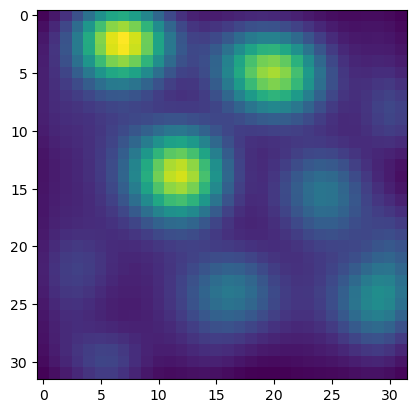

In [3]:
# Instantiate and run the optimization
original_ratemaps = np.load("gc_ratmaps.npy").astype("float32")
original_ratemaps = np.transpose(original_ratemaps, (1,2,0))
plt.imshow(original_ratemaps[...,0])

ratemaps = torch.tensor(original_ratemaps)


In [4]:

# place_ratemaps = joblib.load("./QLAK-CA1-50_rate_maps")["maps"]["smoothed"][...,0]

# nan_mask = np.isnan(np.mean(place_ratemaps, axis = (0, 1))) # remove all-nan maps
# original_ratemaps = place_ratemaps[...,~nan_mask]
# # remove nans
# original_ratemaps = np.array([astropy.convolution.convolve(original_ratemaps[...,i], astropy.convolution.Gaussian2DKernel(2), boundary='extend') for i in range(original_ratemaps.shape[-1])])
# original_ratemaps = np.transpose(original_ratemaps, (1, 2, 0))

# ratemaps = torch.tensor(original_ratemaps.astype("float32"))[...,:100]#[4:-4, 4:-4]
# plt.imshow(torch.linalg.norm(ratemaps, dim =-1), vmin = 0)
# plt.colorbar()
# ax = ratemap_collage(ratemaps.numpy().transpose(2, 0, 1)[:100], 10)
# print(place_ratemaps.shape, original_ratemaps.shape, ratemaps.shape)


In [5]:
ratemaps.shape

torch.Size([32, 32, 102])

In [6]:
model = OptimizationModel(d = ratemaps.shape[-1])

In [7]:
loss_history = model.optimize(10000, ratemaps)

100%|██████████| 10000/10000 [03:53<00:00, 42.82it/s]


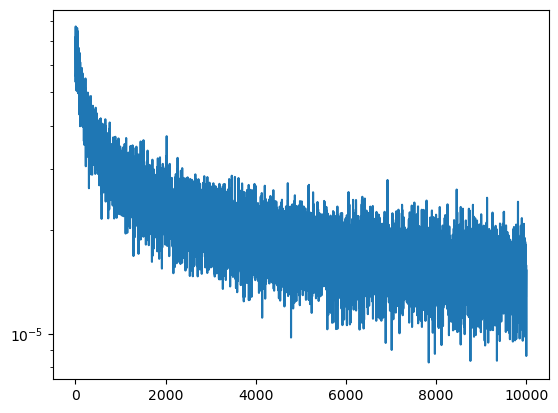

In [8]:
plt.semilogy(model.loss_history)

In [43]:

genny = SimpleDatasetMaker(rayleigh_scale=0.1, chamber_size=2)

steps = 10000
r, v = genny.generate_dataset(100, steps)
ind = torch.argmin(torch.linalg.norm(r[:,0], axis=  -1)) # center!
r = r[ind]
v = v[ind]
r = r.squeeze()
v = v.squeeze()
r.min(), v.max(), v.min()
print(r.shape)
r = r - r[0,None]

torch.Size([10000, 2])


In [44]:
print(r[0])

tensor([0., 0.])


(-2.1573919117450715,
 2.239205127954483,
 -2.157688242197037,
 2.2413210690021517)

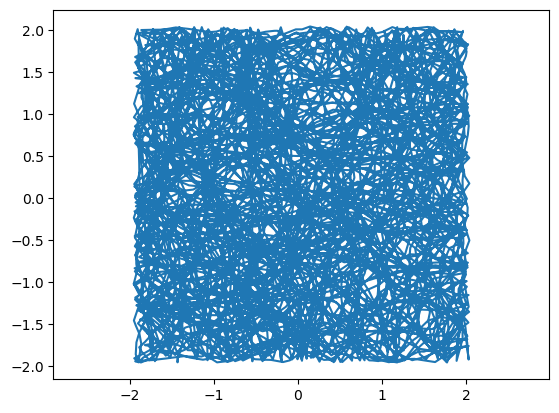

In [45]:
plt.plot(r[:,0], r[:,1])
plt.axis("equal")

In [46]:
# only generation 
p_prime = torch.full((ratemaps.shape[-1], steps), torch.nan, dtype = torch.float32)
p_prime[:,0] = ratemaps[ratemaps.shape[0]//2,ratemaps.shape[1]//2]

for i in range(steps-1):
    z = p_prime[:,i]
    dr = v[i]
    theta = np.arctan2(dr[1], dr[0])
    m = torch.sqrt(dr[0]**2 + dr[1]**2)
    C = m*(torch.cos(theta)*model.A + torch.sin(theta)*model.B)
    Q = torch.matrix_exp(C)
    p_prime[:,i+1] = Q@z

p_prime = p_prime.detach().numpy()

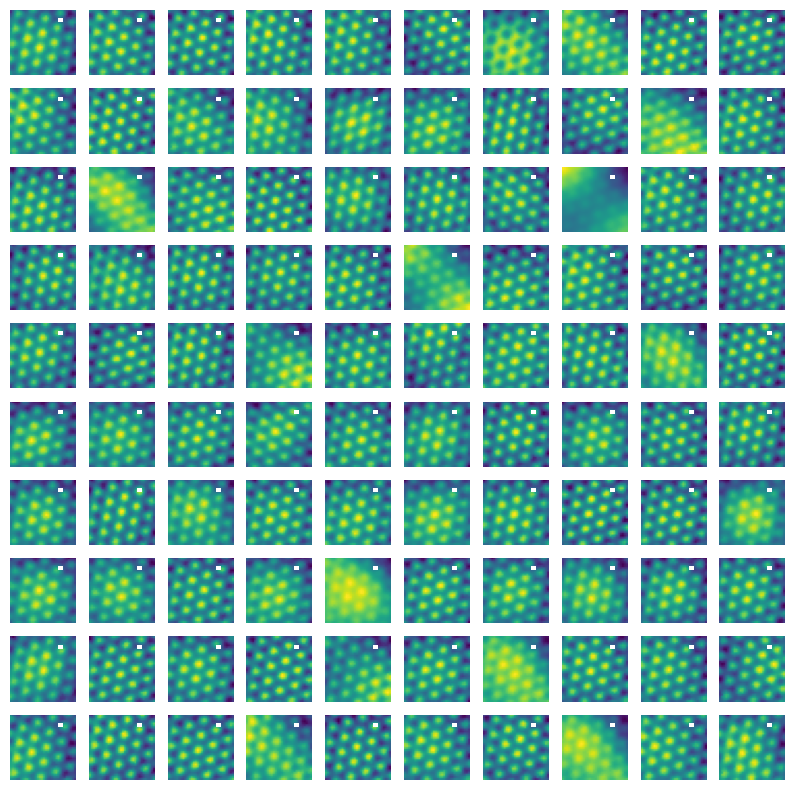

In [47]:
import scipy
bins = original_ratemaps.shape[0]
pp_prime = scipy.stats.binned_statistic_2d(r[:,0], r[:,1], p_prime, bins = 32)[0]

R = lambda x: np.maximum(0, x)
if relu := False:
    pp_prime = R(pp_prime)
fig, axs = ratemap_collage(pp_prime[:100],10, figsize = (10, 10))

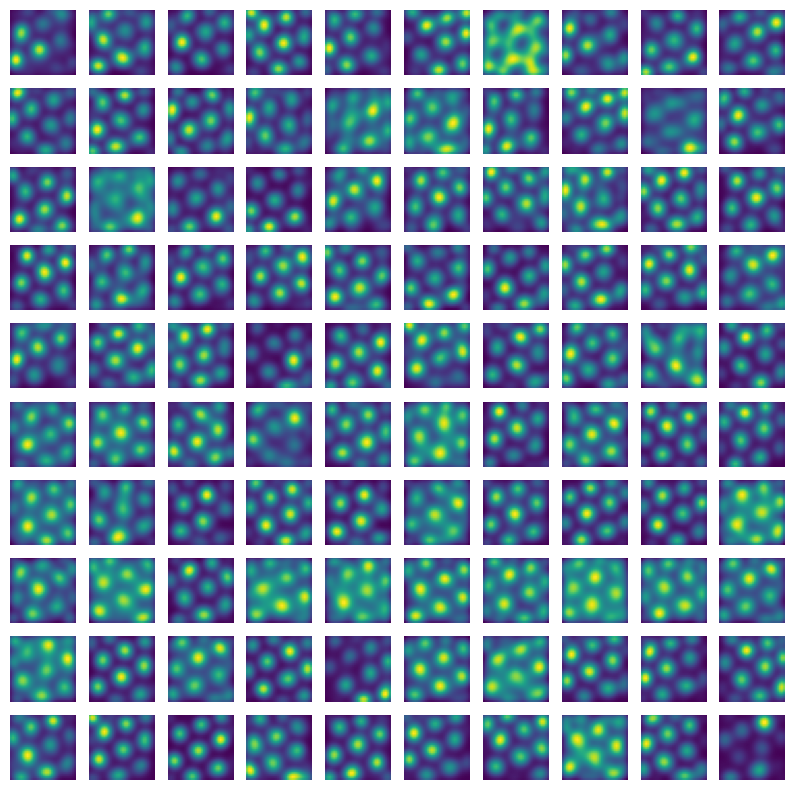

In [14]:
ratemap_collage(original_ratemaps.transpose(2, 0, 1)[:100], 10, figsize = (10,10));

Text(0.5, 1.0, 'Learned Norm')

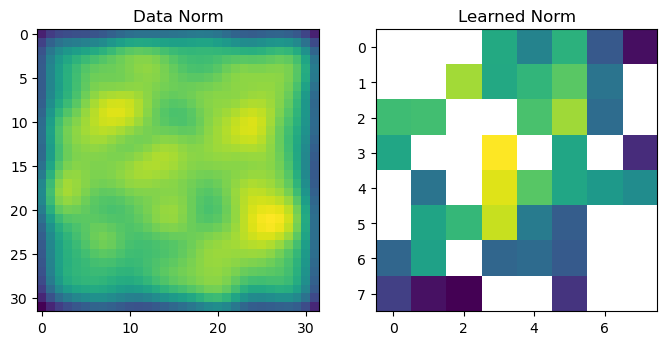

In [15]:
fig, ax = plt.subplots(1, 2, figsize = (8, 4))
ax[0].imshow(np.linalg.norm(ratemaps, axis = -1))
ax[1].imshow(np.linalg.norm(pp_prime, axis = 0))
ax[0].set_title("Data Norm")
ax[1].set_title("Learned Norm")

In [16]:
plt.figure(figsize = (5,5))
a = original_ratemaps.shape[0]//2
b = original_ratemaps.shape[1]//2 

dp_data = np.nansum((original_ratemaps - original_ratemaps[a,b,None,None])**2,axis=-1)
dp_learned = np.nansum((pp_prime - pp_prime[:,a,b,None,None])**2,axis=0)

fig, ax = plt.subplots(1, 2, figsize = (8, 4))
ax[0].imshow(dp_data)
ax[1].imshow(dp_learned)
ax[0].plot(b,a, "wx", markersize = 5)
ax[1].plot(b,a, "wx", markersize = 5)
ax[0].set_title("Data")
ax[1].set_title("Learned")

IndexError: index 16 is out of bounds for axis 1 with size 8

<Figure size 500x500 with 0 Axes>

In [ ]:
theta = np.pi/2
step_size = 2/32
Ql = torch.matrix_exp(step_size*(np.cos(theta)*model.A + np.sin(theta)*model.B))
plt.imshow((Ql).detach().numpy())
plt.colorbar()